In [66]:
from datetime import datetime
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
# df = pd.read_csv("/home/claus/Repository/rpy_velutina/BME280_nicholas/data_temp_senseca/pro_line_log_20261110154337_0.csv", sep=";")
df = pd.read_csv("/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/data_temp_senseca/pro_line_log_20261110154337_0.csv", sep=";")
df["date"] = pd.to_datetime(df["date"])
df = df.set_index('date')

In [3]:
# df

In [4]:
# nur die Werte nehmen, die am nächsten an der 10-Minuten-Marke sind

df.index = df.index.floor("1min")
df = df[df.index == df.index.floor('10min')]
# df_res10 = df.resample('10min').mean()

In [5]:
# df

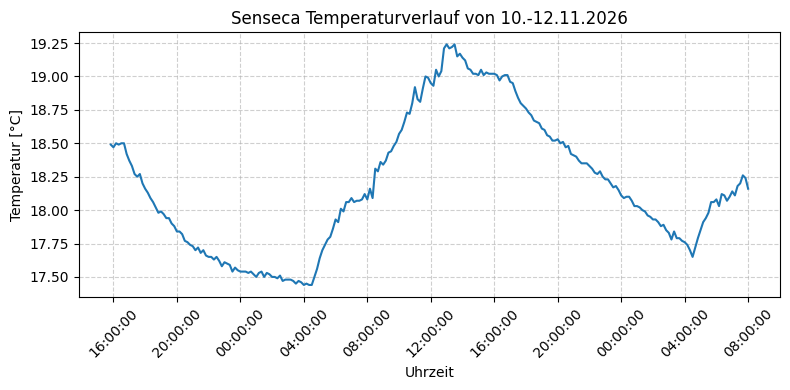

In [6]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4))
plt.plot(df.index, df["temp"])

# Achsen und Layout formatieren
plt.title("Senseca Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()


In [7]:
df_picos = pd.read_csv("/home/illich/Masterarbeit/rpy_velutina/BME280_nicholas/src/data/data_pico2-7_1011_1211.csv", sep=",")
df_picos["_time"] = pd.to_datetime(df_picos["_time"], format="mixed")

In [8]:
# df_picos

In [9]:
df_picos = df_picos[["_time", "_value", "DEVICE_ID"]]
df_picos.columns = ['date', 'temp', 'id']
df_picos = df_picos.set_index('date')
df_picos.index = df_picos.index.tz_localize(None)

In [10]:
# df_picos

In [11]:
df_pico2 = df_picos[df_picos["id"] == "pico_2"][2:-15]
df_pico3 = df_picos[df_picos["id"] == "pico_3"][2:-15]
df_pico4 = df_picos[df_picos["id"] == "pico_4"][2:-15]
df_pico5 = df_picos[df_picos["id"] == "pico_5"][2:-14]
df_pico6 = df_picos[df_picos["id"] == "pico_6"][2:-15]
df_pico7 = df_picos[df_picos["id"] == "pico_7"][2:-15]

In [12]:
picos_dfs = [df_pico2, df_pico3, df_pico4, df_pico5, df_pico6, df_pico7]

In [13]:
picos_dfs_names = ["Pico_2", "Pico_3", "Pico_4", "Pico_5", "Pico_6", "Pico_7"]

In [14]:
len(df_pico2), len(df_pico3), len(df_pico4), len(df_pico5), len(df_pico6), len(df_pico7), 

(242, 242, 242, 242, 242, 242)

In [44]:
summary = ergebnis = pd.concat(picos_dfs, axis=1)
summary = summary.drop(columns=['id'])
summary.columns = picos_dfs_names

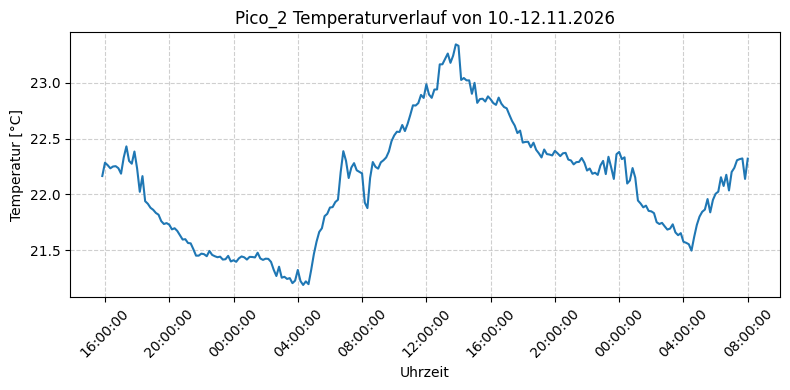

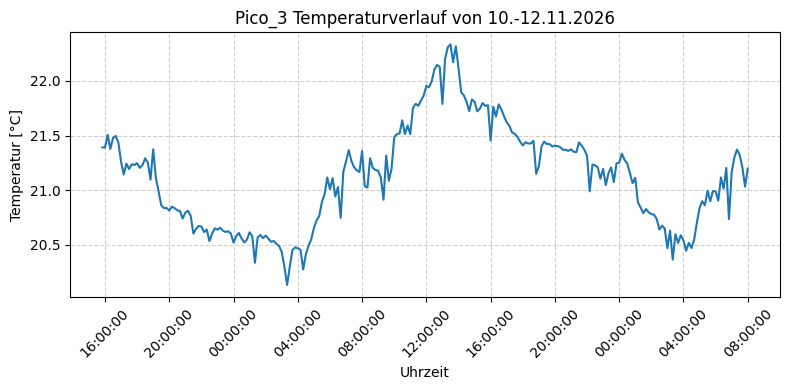

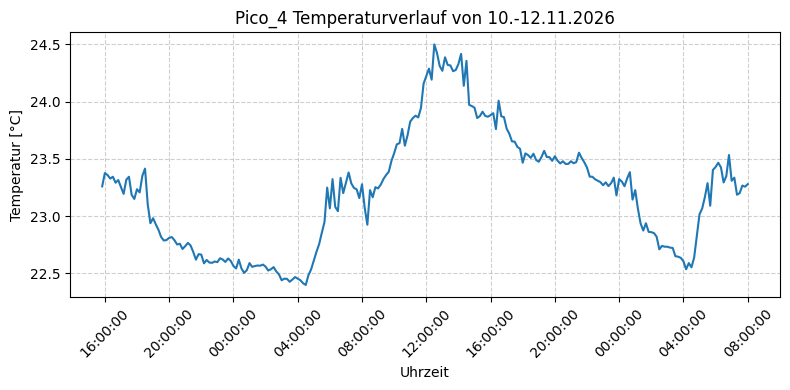

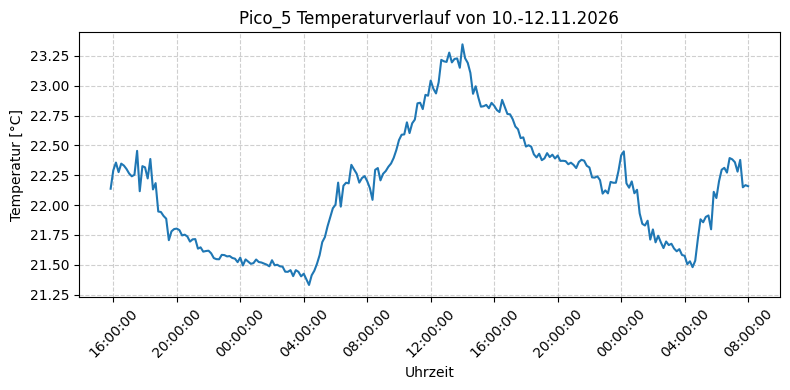

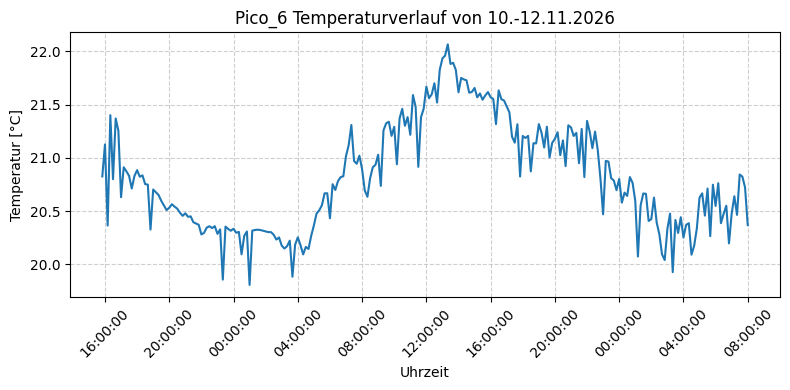

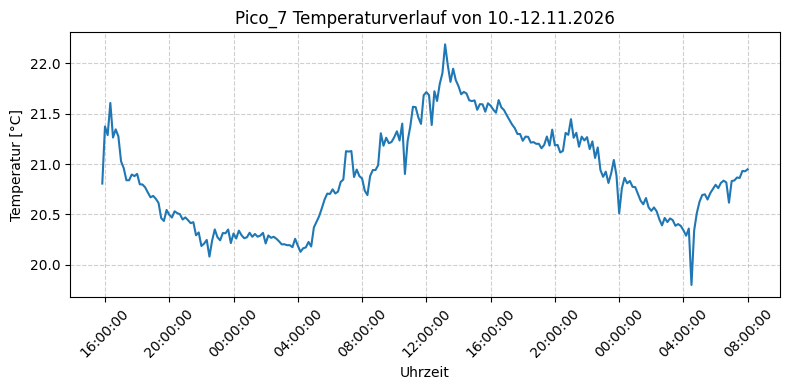

In [15]:
for df_pico, name in zip(picos_dfs, picos_dfs_names):
    # Diagramm zeichnen
    plt.figure(figsize=(8, 4))
    plt.plot(df_pico.index, df_pico["temp"])

    # Achsen und Layout formatieren
    plt.title(name + " Temperaturverlauf von 10.-12.11.2026")
    plt.xlabel("Uhrzeit")
    plt.ylabel("Temperatur [°C]")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    plt.xticks(rotation=45)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()

    plt.show()

In [16]:
diff_lst = []
for df_pico, name in zip(picos_dfs, picos_dfs_names):
    diff = df_pico["temp"].values - df["temp"].values
    diff_lst.append(diff)

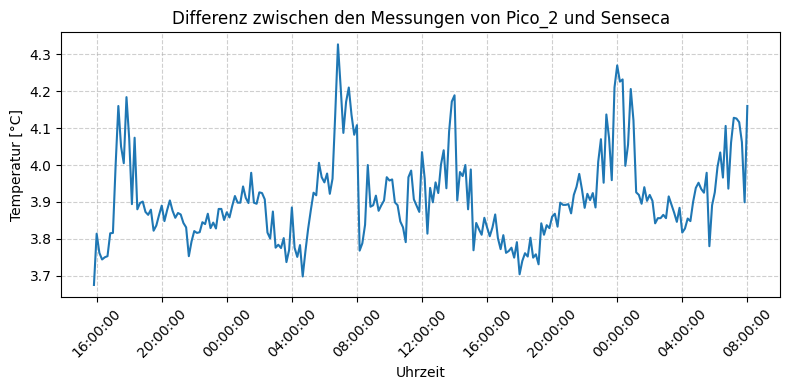

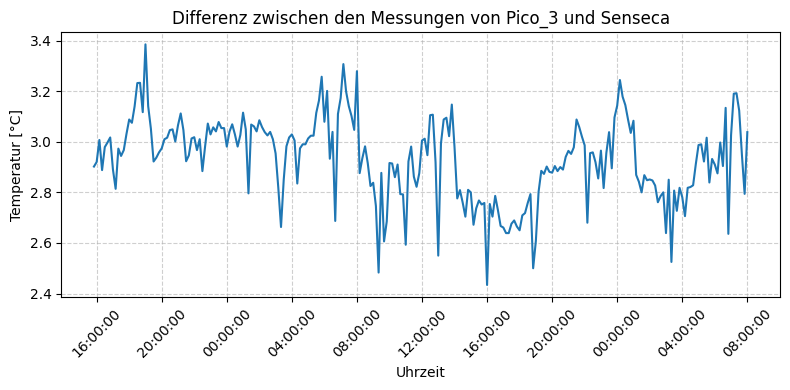

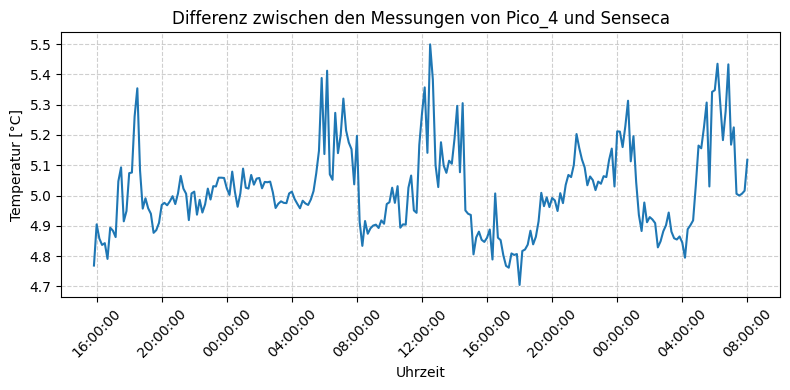

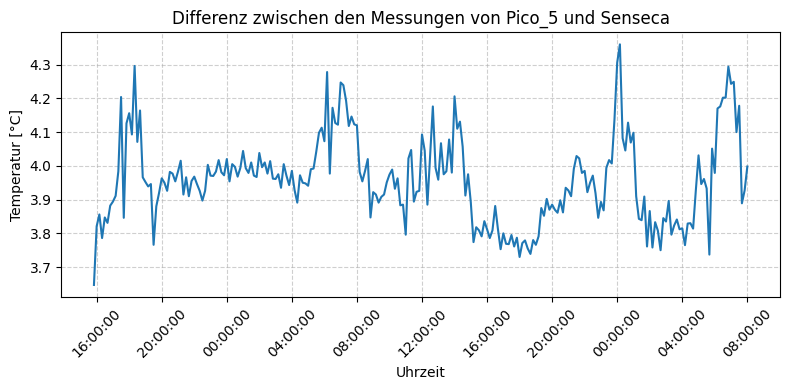

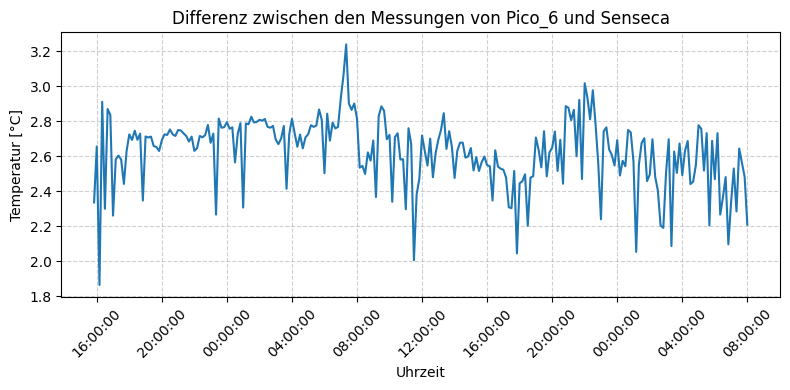

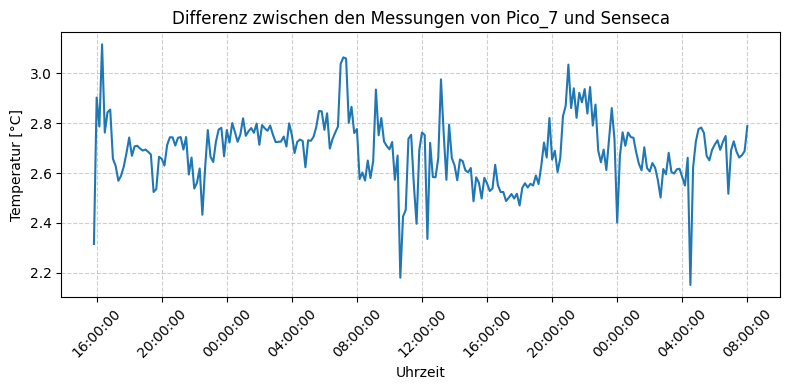

In [17]:
for diff, name in zip(diff_lst, picos_dfs_names):
    # Diagramm zeichnen
    plt.figure(figsize=(8, 4))
    plt.plot(df.index, diff)

    # Achsen und Layout formatieren
    plt.title("Differenz zwischen den Messungen von " + name + " und Senseca")
    plt.xlabel("Uhrzeit")
    plt.ylabel("Temperatur [°C]")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    plt.xticks(rotation=45)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()

    plt.show()

In [18]:
print("Mittelwerte und Standardabweichung der Differnez zwischen Pico und Senseca:\n")
for diff, name in zip(diff_lst, picos_dfs_names):
    print(name + ":    Mean " + str(diff.mean().round(2)) + "    Std " + str(diff.std().round(2)))

Mittelwerte und Standardabweichung der Differnez zwischen Pico und Senseca:

Pico_2:    Mean 3.91    Std 0.12
Pico_3:    Mean 2.93    Std 0.16
Pico_4:    Mean 5.02    Std 0.14
Pico_5:    Mean 3.96    Std 0.13
Pico_6:    Mean 2.62    Std 0.2
Pico_7:    Mean 2.69    Std 0.13


In [ ]:
diff_lst = []
for df_pico_comp in picos_dfs:
    diff_lst_comp = []
    for df_pico, name in zip(picos_dfs, picos_dfs_names):
        diff = df_pico["temp"].values - df_pico_comp["temp"].values
        diff_lst_comp.append(diff)
    diff_lst.append(diff_lst_comp)

In [35]:
print("Mittelwerte und Standardabweichung der Differnez zwischen...")
for i in range(len(diff_lst)):
    print("\nPico_" + str(i+2) + " und...")
    for diff, name in zip(diff_lst[i], picos_dfs_names):
        print(name + ":    Mean " + str(diff.mean().round(2)) + "    Std " + str(diff.std().round(2)))

Mittelwerte und Standardabweichung der Differnez zwischen...

Pico_2 und...
Pico_2:    Mean 0.0    Std 0.0
Pico_3:    Mean -0.98    Std 0.15
Pico_4:    Mean 1.11    Std 0.12
Pico_5:    Mean 0.05    Std 0.09
Pico_6:    Mean -1.29    Std 0.21
Pico_7:    Mean -1.22    Std 0.15

Pico_3 und...
Pico_2:    Mean 0.98    Std 0.15
Pico_3:    Mean 0.0    Std 0.0
Pico_4:    Mean 2.09    Std 0.15
Pico_5:    Mean 1.03    Std 0.13
Pico_6:    Mean -0.31    Std 0.2
Pico_7:    Mean -0.25    Std 0.15

Pico_4 und...
Pico_2:    Mean -1.11    Std 0.12
Pico_3:    Mean -2.09    Std 0.15
Pico_4:    Mean 0.0    Std 0.0
Pico_5:    Mean -1.06    Std 0.09
Pico_6:    Mean -2.39    Std 0.21
Pico_7:    Mean -2.33    Std 0.15

Pico_5 und...
Pico_2:    Mean -0.05    Std 0.09
Pico_3:    Mean -1.03    Std 0.13
Pico_4:    Mean 1.06    Std 0.09
Pico_5:    Mean 0.0    Std 0.0
Pico_6:    Mean -1.33    Std 0.2
Pico_7:    Mean -1.27    Std 0.14

Pico_6 und...
Pico_2:    Mean 1.29    Std 0.21
Pico_3:    Mean 0.31    Std 0.2
Pic

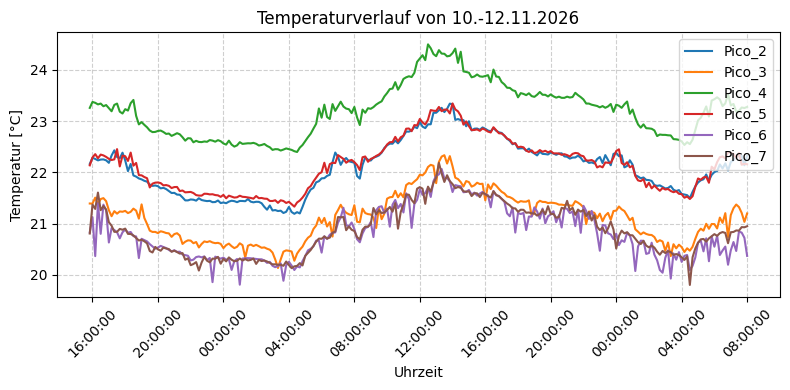

In [52]:
# Diagramm zeichnen
plt.figure(figsize=(8, 4))
plt.plot(summary.index, summary)

# Achsen und Layout formatieren
plt.title("Temperaturverlauf von 10.-12.11.2026")
plt.xlabel("Uhrzeit")
plt.ylabel("Temperatur [°C]")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.legend(summary.columns)

plt.show()

In [62]:
mean = []
for pico in picos_dfs:
    mean_ = []
    for pico_ in picos_dfs:
        diff = pico_["temp"].values - pico["temp"].values
        mean_.append(diff.mean().round(2))
    mean.append(mean_)

In [63]:
np.array(mean)

array([[ 0.  , -0.98,  1.11,  0.05, -1.29, -1.22],
       [ 0.98,  0.  ,  2.09,  1.03, -0.31, -0.25],
       [-1.11, -2.09,  0.  , -1.06, -2.39, -2.33],
       [-0.05, -1.03,  1.06,  0.  , -1.33, -1.27],
       [ 1.29,  0.31,  2.39,  1.33,  0.  ,  0.06],
       [ 1.22,  0.25,  2.33,  1.27, -0.06,  0.  ]])

In [64]:
std = []
for pico in picos_dfs:
    std_ = []
    for pico_ in picos_dfs:
        diff = pico_["temp"].values - pico["temp"].values
        std_.append(diff.std().round(2))
    std.append(std_)

In [65]:
np.array(std)

array([[0.  , 0.15, 0.12, 0.09, 0.21, 0.15],
       [0.15, 0.  , 0.15, 0.13, 0.2 , 0.15],
       [0.12, 0.15, 0.  , 0.09, 0.21, 0.15],
       [0.09, 0.13, 0.09, 0.  , 0.2 , 0.14],
       [0.21, 0.2 , 0.21, 0.2 , 0.  , 0.17],
       [0.15, 0.15, 0.15, 0.14, 0.17, 0.  ]])